In [1]:
import numpy as np
import re
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cmcrameri import cm
from cartopy.util import add_cyclic_point
import sys
from pathlib import Path
sys.path.insert(0, str(Path("../src").resolve()))
import windrisk as wr

Load in the track file for each extended winter:

In [2]:
track_path="/uolstore/RIT/RITCore/Env/p0103/eewo/ERA5/cyclone_tracks"

In [3]:
#Open track data for a specific year
year = 1980
tracks_ = wr.open_track_dataset(track_path,year)

Calculate the track density of all the track centres

In [ ]:
yr_st=1980
yr_end=2026
lon_grid = np.array(list(range(-110,61,1)))
lat_grid = np.array(list(range(90,-1,-1)))

In [ ]:
track_density = np.zeros((len(lat_grid),len(lon_grid)))
for year in range(yr_st,yr_end):
    if year != 1982:
        lines = wr.open_track_dataset(track_path,year)
        for li in lines:
            if 'start' in li:
                pass
            else:
                track_density[int(li[1]),int(li[0])]+=1


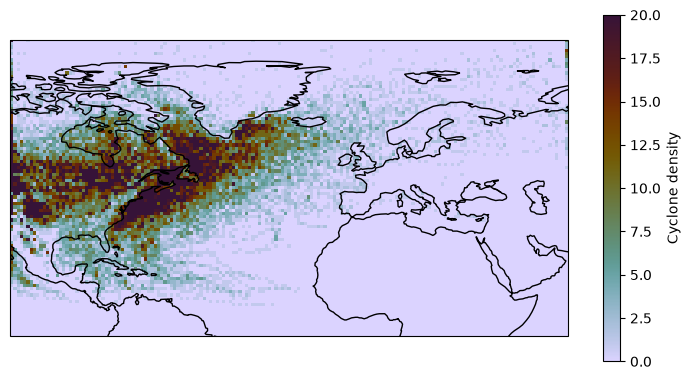

In [8]:


fig, ax = plt.subplots(
    figsize=(9, 9),
    subplot_kw={"projection": ccrs.PlateCarree()},
)



plot = ax.pcolormesh(lon_grid,lat_grid, track_density,transform=ccrs.PlateCarree(), cmap=cm.glasgow_r,vmin=0,vmax=20)

ax.coastlines()


fig.colorbar(
    plot, ax=ax,shrink=0.5,
    label="Cyclone density",
)

plt.show()